# Assignment II (Set A): Robust RL under Sticky Actuators
Q-learning vs SARSA on `MountainCar-v0` with a sticky-actuator wrapper.

**Group #:** <<ENTER>> &nbsp; **Members / contribution %:** <<ENTER>>

*Run this notebook top to bottom (about 10 minutes). Add your virtual-lab screenshots at the end.*

## 0. Setup and shared library
Imports, constants, the gentle-arrival test, wrapper, discretizer, shared training loop and evaluation helpers. The training loop is shared by both algorithms; only the TD target differs.

In [1]:
import numpy as np
import gymnasium as gym

# ----------------------------------------------------------------------------------------
# Constants taken directly from the assignment text
# ----------------------------------------------------------------------------------------
STICK_PROB = 0.20        # r < 0.20  -> actuator stuck
PUSH_PENALTY = 0.2       # energy penalty for selected action in {0, 2}
ARRIVAL_BONUS = 20.0     # gentle-arrival bonus B
ARRIVAL_SPEED = 0.04     # observation[1] <= 0.04 counts as "gentle"
GOAL_POS = 0.5
N_ACTIONS = 3


def is_gentle_arrival(obs, terminated, truncated):
    """Gentle-arrival criterion (Step 5): terminated, not truncated, pos>=0.5, vel<=0.04."""
    return bool(terminated and (not truncated)
                and obs[0] >= GOAL_POS and obs[1] <= ARRIVAL_SPEED)

## (a) Modified environment
`StickyMountainCar` follows Steps 1-6 exactly: store `a`, sticky replacement with p=0.20 only when `a != a_prev`, execute `a_exec`, `R = R_base - 0.2*1[a!=1] + B`, bonus only on gentle arrival, `info` untouched, `a_prev=1` on reset.

In [2]:
def is_gentle_arrival(obs, terminated, truncated):
    """Gentle-arrival criterion (Step 5): terminated, not truncated, pos>=0.5, vel<=0.04."""
    return bool(terminated and (not truncated)
                and obs[0] >= GOAL_POS and obs[1] <= ARRIVAL_SPEED)


class StickyMountainCar(gym.Wrapper):
    """MountainCar-v0 with a sticky actuator and a modified reward.

    Internal state : a_prev (action actually executed on the previous step; 1 after reset).
    step(a):
      1. store agent action a
      2. if a != a_prev, draw r~U[0,1); if r < 0.20 -> a_exec = a_prev else a_exec = a
         (if a == a_prev nothing is drawn and a_exec = a)
      3. execute a_exec in the base env
      4. R = R_base - 0.2 * 1[a != 1] + B   (a is the AGENT's action, not a_exec)
      5. B = +20 iff terminated and not truncated and pos >= 0.5 and vel <= 0.04
      6. return obs, R, terminated, truncated, info  (info is the untouched base info)
    The agent is never told whether its action was replaced.
    """

    def __init__(self, env, seed=None, stick_prob=STICK_PROB):
        super().__init__(env)
        self.stick_prob = stick_prob
        self.a_prev = 1
        # Dedicated generator for the actuator so that results are reproducible and
        # independent of the base env / agent random streams.
        self._rng = np.random.default_rng(seed)
        # Diagnostics (NOT exposed to the agent; only read by the verification code).
        self.last_a_exec = None
        self.last_replaced = False
        self.last_r = None        # random number drawn on the last step (None if none drawn)
        self.last_bonus = 0.0

    def reset(self, **kwargs):
        self.a_prev = 1                      # "Do not accelerate" at the start of every episode
        self.last_a_exec, self.last_replaced, self.last_r, self.last_bonus = None, False, None, 0.0
        return self.env.reset(**kwargs)

    def step(self, action):
        a = int(action)                                   # Step 1: store agent's action
        # Step 2: sticky actuator
        self.last_r = None
        if a == self.a_prev:
            a_exec = a                                    # repeating the previous action: never replaced
        else:
            r = self._rng.random()                        # r ~ U[0, 1)
            self.last_r = r
            a_exec = self.a_prev if r < self.stick_prob else a
        self.last_replaced = (a_exec != a)
        self.last_a_exec = a_exec
        self.a_prev = a_exec                              # a_prev <- a_exec
        # Step 3: execute in the original env
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)
        # Steps 4 & 5: modified reward (penalty uses the SELECTED action a)
        bonus = ARRIVAL_BONUS if is_gentle_arrival(obs, terminated, truncated) else 0.0
        reward = r_base - PUSH_PENALTY * (1.0 if a != 1 else 0.0) + bonus
        self.last_bonus = bonus
        # Step 6: return, info untouched
        return obs, reward, terminated, truncated, info


def make_env(modified, seed=0):
    """Build the original (modified=False) or sticky/modified (modified=True) environment."""
    env = gym.make("MountainCar-v0")                      # 200-step TimeLimit is built in
    return StickyMountainCar(env, seed=seed) if modified else env

## Discretization, exploration and the shared TD-control loop (parts b, c)
Q-table shape (20, 20, 3) initialised to zero. Q-learning target: `R + gamma*max Q(s',.)`; SARSA target: `R + gamma*Q(s',a')`. No bootstrap on termination; truncation still bootstraps.

In [3]:
class Discretizer:
    """Uniform grid over [low, high] per dimension; state -> (i, j) bin indices."""

    def __init__(self, low, high, bins):
        self.low = np.asarray(low, dtype=np.float64)
        self.high = np.asarray(high, dtype=np.float64)
        self.bins = np.asarray(bins, dtype=int)
        self.width = (self.high - self.low) / self.bins

    def __call__(self, obs):
        idx = ((np.asarray(obs, dtype=np.float64) - self.low) / self.width).astype(int)
        idx = np.clip(idx, 0, self.bins - 1)              # edge values fall in the last bin
        return int(idx[0]), int(idx[1])


def make_discretizer(n_pos=20, n_vel=20):
    """MountainCar-v0 ranges: position [-1.2, 0.6], velocity [-0.07, 0.07]."""
    return Discretizer([-1.2, -0.07], [0.6, 0.07], [n_pos, n_vel])


def epsilon_greedy(Q, s, eps, rng):
    """With prob eps pick a uniform random action, else argmax_a Q[s, a] (random tie-break)."""
    if rng.random() < eps:
        return int(rng.integers(N_ACTIONS))
    q = Q[s[0], s[1]]
    best = np.flatnonzero(q == q.max())
    return int(rng.choice(best)) if len(best) > 1 else int(best[0])


def epsilon_schedule(ep, n_episodes, eps_start=1.0, eps_end=0.01, decay_frac=0.8):
    """Exponential (geometric) decay from eps_start to eps_end over the first
    decay_frac * n_episodes episodes, then constant at eps_end."""
    decay_eps = decay_frac * n_episodes
    if ep >= decay_eps:
        return eps_end
    return eps_start * (eps_end / eps_start) ** (ep / decay_eps)


def train_agent(algo, modified, disc, n_episodes=5000, alpha=0.1, gamma=0.99,
                eps_start=1.0, eps_end=0.01, decay_frac=0.8, seed=0, val_states=None):
    """Train a tabular agent.

    algo     : 'q_learning' (target R + gamma*max_a' Q(s',a')) or
               'sarsa'      (target R + gamma*Q(s',a'), a' = next eps-greedy action)
    modified : True -> sticky/modified env, False -> original MountainCar-v0
    The Q-table has shape (pos_bins, vel_bins, 3) and is initialised to zero.
    Bootstrapping is skipped only on TERMINATION (truncation is not terminal).
    Returns Q and a dict of per-episode training logs.
    """
    assert algo in ("q_learning", "sarsa")
    env = make_env(modified, seed=seed)
    rng = np.random.default_rng(seed)                     # agent's exploration randomness
    Q = np.zeros((*disc.bins, N_ACTIONS))
    log = {k: np.zeros(n_episodes) for k in
           ("reward", "success", "gentle", "pushes", "length", "val_value")}

    for ep in range(n_episodes):
        eps = epsilon_schedule(ep, n_episodes, eps_start, eps_end, decay_frac)
        obs, _ = env.reset(seed=seed if ep == 0 else None)  # seed env once -> reproducible stream
        s = disc(obs)
        a = epsilon_greedy(Q, s, eps, rng)
        total, pushes, success, gentle, steps = 0.0, 0, 0, 0, 0
        done = False
        while not done:
            obs2, R, terminated, truncated, _ = env.step(a)
            s2 = disc(obs2)
            pushes += int(a != 1)                          # count SELECTED push actions
            total += R
            steps += 1
            a2 = epsilon_greedy(Q, s2, eps, rng)           # a' actually chosen by the policy
            if terminated:                                 # no bootstrap on true termination
                target = R
            elif algo == "q_learning":
                target = R + gamma * Q[s2[0], s2[1]].max()           # off-policy: max_a' Q(s',a')
            else:
                target = R + gamma * Q[s2[0], s2[1], a2]             # on-policy : Q(s',a')
            Q[s[0], s[1], a] += alpha * (target - Q[s[0], s[1], a])  # 'a' = agent-selected action
            if terminated:
                success = 1
                gentle = int(is_gentle_arrival(obs2, terminated, truncated))
            s, a = s2, a2
            done = terminated or truncated
        log["reward"][ep], log["pushes"][ep], log["length"][ep] = total, pushes, steps
        log["success"][ep], log["gentle"][ep] = success, gentle
        if val_states is not None:                         # avg_s max_a Q(s,a) on fixed states
            log["val_value"][ep] = avg_max_q(Q, disc, val_states)
    env.close()
    return Q, log


def sample_validation_states(n=500, seed=12345):
    """Fixed validation set sampled ONCE (uniformly over the state box) before training."""
    rng = np.random.default_rng(seed)
    pos = rng.uniform(-1.2, 0.6, n)
    vel = rng.uniform(-0.07, 0.07, n)
    return np.stack([pos, vel], axis=1)


def avg_max_q(Q, disc, states):
    """Average predicted value: mean over validation states of max_a Q(s, a)."""
    return float(np.mean([Q[disc(s)].max() for s in states]))

## Evaluation helpers

In [4]:
def greedy_policy_map(Q):
    """argmax_a Q over the grid -> array (pos_bins, vel_bins) of greedy actions."""
    return Q.argmax(axis=2)


def evaluate_greedy(Q, disc, modified, n_episodes=100, base_seed=1000):
    """Run the greedy policy (eps=0) for n_episodes with fixed seeds (base_seed + i)."""
    env = make_env(modified, seed=base_seed)
    rewards, succ, gent, lens, speeds = [], [], [], [], []
    for i in range(n_episodes):
        if modified:
            env._rng = np.random.default_rng(base_seed + i)   # fixed sticky stream per test episode
        obs, _ = env.reset(seed=base_seed + i)
        total, steps, done = 0.0, 0, False
        while not done:
            q = Q[disc(obs)]
            a = int(np.flatnonzero(q == q.max())[0])           # deterministic greedy
            obs, R, term, trunc, _ = env.step(a)
            total += R
            steps += 1
            done = term or trunc
        rewards.append(total)
        succ.append(int(term))
        gent.append(int(is_gentle_arrival(obs, term, trunc)))
        lens.append(steps)
        if term:
            speeds.append(obs[1])
    env.close()
    return {"mean_reward": float(np.mean(rewards)), "success_rate": float(np.mean(succ)),
            "gentle_rate": float(np.mean(gent)), "mean_length": float(np.mean(lens)),
            "mean_arrival_speed": float(np.mean(speeds)) if speeds else float("nan")}


def moving_average(x, w=100):
    """Trailing moving average over the previous w episodes (shorter window at the start)."""
    c = np.cumsum(np.insert(np.asarray(x, dtype=float), 0, 0.0))
    out = np.empty(len(x))
    for i in range(len(x)):
        lo = max(0, i + 1 - w)
        out[i] = (c[i + 1] - c[lo]) / (i + 1 - lo)
    return out

## Experiment configuration (identical for all four agents)

In [5]:
import json, os, sys, time, datetime, platform
import numpy as np
import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display

OUT = os.path.join(os.getcwd(), "outputs")
os.makedirs(OUT, exist_ok=True)
LOG = open(os.path.join(OUT, "log.txt"), "w")


def P(*args):
    """print() to both the console and outputs/log.txt."""
    msg = " ".join(str(a) for a in args)
    print(msg)
    LOG.write(msg + "\n")
    LOG.flush()


# ---------------------------------------------------------------------------------------
# Experimental configuration (IDENTICAL for Q-learning and SARSA, original and modified)
# ---------------------------------------------------------------------------------------
CFG = dict(seed=0, n_pos=20, n_vel=20, n_episodes=5000, alpha=0.1, gamma=0.99,
           eps_start=1.0, eps_end=0.01, decay_frac=0.8, n_val_states=500,
           n_test_episodes=100, test_base_seed=1000)
ROBUST_SEEDS = [1, 2, 3, 4]          # extra seeds (main seed is CFG['seed']) for robustness table
AGENTS = [("q_learning", False), ("sarsa", False), ("q_learning", True), ("sarsa", True)]


def name_of(algo, modified):
    return f"{'Q-learning' if algo == 'q_learning' else 'SARSA'} - {'Modified' if modified else 'Original'}"


STYLE = {  # colour = algorithm, line style = environment
    "Q-learning - Original": dict(color="#1f77b4", ls="--"),
    "SARSA - Original": dict(color="#d95f02", ls="--"),
    "Q-learning - Modified": dict(color="#1f77b4", ls="-"),
    "SARSA - Modified": dict(color="#d95f02", ls="-"),
}

## (a) Verification routines and results

In [6]:
class ScriptedRNG:
    """Stand-in RNG that returns pre-scripted numbers (used to replay the assignment's example)."""

    def __init__(self, values):
        self.values = list(values)

    def random(self):
        return self.values.pop(0)


def verify_example_table():
    """Replays the 5-step example table from the assignment with scripted random numbers."""
    P("\n[a.1] Deterministic replay of the example table in the assignment")
    env = StickyMountainCar(gym.make("MountainCar-v0"))
    env.reset(seed=0)
    agent_actions = [2, 2, 0, 0, 1]
    scripted_r = [0.55, 0.11, 0.74, 0.05]            # step 2 (a == a_prev) draws NO random number
    expected = [2, 2, 2, 0, 0]
    env._rng = ScriptedRNG(scripted_r)
    P(f"{'Step':<5}{'a_prev':<8}{'a':<4}{'r':<8}{'a_exec':<8}{'expected':<9}{'ok'}")
    all_ok = True
    for i, a in enumerate(agent_actions):
        a_prev = env.a_prev
        env.step(a)
        ok = env.last_a_exec == expected[i]
        all_ok &= ok
        r_txt = "-" if env.last_r is None else f"{env.last_r:.2f}"
        P(f"{i + 1:<5}{a_prev:<8}{a:<4}{r_txt:<8}{env.last_a_exec:<8}{expected[i]:<9}{ok}")
    assert not env._rng.values, "step 2 must not consume a random number"
    P("Example table reproduced exactly:", all_ok)
    return bool(all_ok)


def verify_random_policy(n_episodes=2000, seed=7):
    """Random policy: replacement rate, no-replacement-on-repeat, penalty and bonus checks."""
    P(f"\n[a.2] Random policy, {n_episodes} episodes")
    env = StickyMountainCar(gym.make("MountainCar-v0"), seed=seed)
    rng = np.random.default_rng(seed)
    n_steps = n_changes = n_replaced_on_change = n_replaced_on_repeat = n_repeats = 0
    pen_push = pen_push_ok = nopen_a1 = nopen_a1_ok = 0
    bonus_steps = bonus_wrong = reset_ok = 0
    reward_mismatch = 0
    for ep in range(n_episodes):
        env.reset(seed=seed + ep)
        reset_ok += int(env.a_prev == 1)             # a_prev must be 1 after reset
        done = False
        while not done:
            a = int(rng.integers(3))
            a_prev = env.a_prev
            obs, R, term, trunc, info = env.step(a)
            done = term or trunc
            n_steps += 1
            if a == a_prev:
                n_repeats += 1
                n_replaced_on_repeat += int(env.last_replaced)
            else:
                n_changes += 1
                n_replaced_on_change += int(env.last_replaced)
            # reward identity: R == -1 - 0.2*1[a!=1] + B
            B = ARRIVAL_BONUS if is_gentle_arrival(obs, term, trunc) else 0.0
            expected = -1.0 - PUSH_PENALTY * (a != 1) + B
            reward_mismatch += int(abs(R - expected) > 1e-9)
            if a != 1:                               # push selected -> penalty must be present
                pen_push += 1
                pen_push_ok += int(abs((R - B) - (-1.0 - PUSH_PENALTY)) < 1e-9)
            else:                                    # action 1 selected -> NO penalty ever
                nopen_a1 += 1
                nopen_a1_ok += int(abs((R - B) - (-1.0)) < 1e-9)
            bonus_steps += int(B > 0)
            bonus_wrong += int((B > 0) != (env.last_bonus > 0))
            assert info == {}, "info dict must stay untouched"
    P(f"total steps                              : {n_steps}")
    P(f"attempted changes (a != a_prev)          : {n_changes}")
    P(f"  replaced by a_prev                     : {n_replaced_on_change} "
      f"({100 * n_replaced_on_change / n_changes:.2f}%  | expected {100 * STICK_PROB:.0f}%)")
    P(f"repeats (a == a_prev)                    : {n_repeats}")
    P(f"  replacements among repeats             : {n_replaced_on_repeat}  (must be 0)")
    P(f"steps with push selected (0 or 2)        : {pen_push}; penalty -0.2 present in {pen_push_ok} (must be all)")
    P(f"steps with action 1 selected             : {nopen_a1}; penalty-free in {nopen_a1_ok} (must be all)")
    P(f"reward == -1 - 0.2*1[a!=1] + B mismatches: {reward_mismatch}  (must be 0)")
    P(f"a_prev == 1 after reset                  : {reset_ok}/{n_episodes}")
    P(f"bonus steps (random policy)              : {bonus_steps}")
    return dict(steps=n_steps, changes=n_changes, replaced=n_replaced_on_change,
                replace_rate=n_replaced_on_change / n_changes, repeats=n_repeats,
                replaced_on_repeat=n_replaced_on_repeat, push_steps=pen_push,
                push_with_penalty=pen_push_ok, a1_steps=nopen_a1, a1_no_penalty=nopen_a1_ok,
                reward_mismatch=reward_mismatch, reset_ok=reset_ok, n_episodes=n_episodes)


def verify_bonus_handcoded(n_episodes=1500, seed=11, noise=0.15):
    """Hand-coded policy (push in direction of velocity, with some noise) to reach the flag often.
    Checks that +20 is awarded iff terminated & not truncated & pos>=0.5 & vel<=0.04."""
    P(f"\n[a.3] Hand-coded policy (push along velocity, {int(noise * 100)}% random actions), {n_episodes} episodes")
    env = StickyMountainCar(gym.make("MountainCar-v0"), seed=seed)
    rng = np.random.default_rng(seed)
    n_term = n_trunc = n_bonus = n_fast = viol = 0
    speeds_bonus, speeds_nobonus = [], []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        done = False
        while not done:
            if rng.random() < noise:
                a = int(rng.integers(3))
            else:
                a = 2 if obs[1] >= 0 else 0
            obs, R, term, trunc, _ = env.step(a)
            done = term or trunc
            bonus_given = env.last_bonus > 0
            criterion = bool(term and not trunc and obs[0] >= 0.5 and obs[1] <= 0.04)
            viol += int(bonus_given != criterion)    # bonus <=> criterion on EVERY step
            if bonus_given and not done:
                viol += 1                            # bonus can only appear on the last step
        if term:
            n_term += 1
            if env.last_bonus > 0:
                n_bonus += 1
                speeds_bonus.append(obs[1])
            else:
                n_fast += 1
                speeds_nobonus.append(obs[1])
        else:
            n_trunc += 1
            assert env.last_bonus == 0
    P(f"episodes reaching the flag (terminated)  : {n_term}")
    P(f"  with +20 bonus (vel <= 0.04)           : {n_bonus}  arrival speeds in [{min(speeds_bonus):.4f}, {max(speeds_bonus):.4f}]")
    P(f"  WITHOUT bonus (vel > 0.04, too fast)   : {n_fast}  arrival speeds in "
      f"[{(min(speeds_nobonus) if speeds_nobonus else float('nan')):.4f}, {(max(speeds_nobonus) if speeds_nobonus else float('nan')):.4f}]")
    P(f"truncated episodes (never any bonus)     : {n_trunc}")
    P(f"bonus/criterion disagreements            : {viol}  (must be 0)")
    return dict(n_term=n_term, n_bonus=n_bonus, n_fast=n_fast, n_trunc=n_trunc, violations=viol,
                n_episodes=n_episodes)


def verify_unchanged_components():
    """Observation / action spaces, time limit and info dict must equal the original env."""
    P("\n[a.4] Components that must remain unchanged")
    base, wrapped = gym.make("MountainCar-v0"), StickyMountainCar(gym.make("MountainCar-v0"))
    ok_obs = base.observation_space == wrapped.observation_space
    ok_act = base.action_space == wrapped.action_space
    P(f"observation space identical: {ok_obs}  ({wrapped.observation_space})")
    P(f"action space identical     : {ok_act}  ({wrapped.action_space})")
    P(f"max episode steps          : base={base.spec.max_episode_steps}, wrapped={wrapped.spec.max_episode_steps}")
    # Sanity: with a == a_prev always (always action 1) the wrapped env equals the base env exactly.
    b_obs, _ = base.reset(seed=3)
    w_obs, _ = wrapped.reset(seed=3)
    same = np.allclose(b_obs, w_obs)
    for _ in range(200):
        b = base.step(1)
        w = wrapped.step(1)
        same &= np.allclose(b[0], w[0]) and b[2] == w[2] and b[3] == w[3]
        if b[2] or b[3]:
            break
    P(f"identical trajectories when the agent only repeats a_prev=1: {bool(same)}")
    return bool(ok_obs and ok_act and same)

## Run log header

In [7]:
    t_start = datetime.datetime.now()
    P("=" * 90)
    P("Assignment II (Set A) - Robust RL under Sticky Actuators: execution log")
    P(f"Run started : {t_start.strftime('%Y-%m-%d %H:%M:%S')}")
    P(f"Platform    : {platform.platform()} | Python {platform.python_version()} | "
      f"numpy {np.__version__} | gymnasium {gym.__version__}")
    P(f"Config      : {CFG}")
    P("=" * 90)

    

Assignment II (Set A) - Robust RL under Sticky Actuators: execution log
Run started : 2026-11-05 17:00:07
Platform    : macOS-26.7.1-arm64-arm-64bit-Mach-O | Python 3.13.2 | numpy 2.1.1 | gymnasium 1.3.0
Config      : {'seed': 0, 'n_pos': 20, 'n_vel': 20, 'n_episodes': 5000, 'alpha': 0.1, 'gamma': 0.99, 'eps_start': 1.0, 'eps_end': 0.01, 'decay_frac': 0.8, 'n_val_states': 500, 'n_test_episodes': 100, 'test_base_seed': 1000}


In [8]:
    P("\n######## PART (a): ENVIRONMENT VERIFICATION ########")
    a_results = dict(example_ok=verify_example_table(), random=verify_random_policy(),
                     handcoded=verify_bonus_handcoded(), unchanged_ok=verify_unchanged_components())

    


######## PART (a): ENVIRONMENT VERIFICATION ########

[a.1] Deterministic replay of the example table in the assignment
Step a_prev  a   r       a_exec  expected ok
1    1       2   0.55    2       2        True
2    2       2   -       2       2        True
3    2       0   0.11    2       2        True
4    2       0   0.74    0       0        True
5    0       1   0.05    0       0        True
Example table reproduced exactly: True

[a.2] Random policy, 2000 episodes


total steps                              : 400000
attempted changes (a != a_prev)          : 266817
  replaced by a_prev                     : 53028 (19.87%  | expected 20%)
repeats (a == a_prev)                    : 133183
  replacements among repeats             : 0  (must be 0)
steps with push selected (0 or 2)        : 266584; penalty -0.2 present in 266584 (must be all)
steps with action 1 selected             : 133416; penalty-free in 133416 (must be all)
reward == -1 - 0.2*1[a!=1] + B mismatches: 0  (must be 0)
a_prev == 1 after reset                  : 2000/2000
bonus steps (random policy)              : 0

[a.3] Hand-coded policy (push along velocity, 15% random actions), 1500 episodes


episodes reaching the flag (terminated)  : 1465
  with +20 bonus (vel <= 0.04)           : 855  arrival speeds in [0.0052, 0.0400]
  WITHOUT bonus (vel > 0.04, too fast)   : 610  arrival speeds in [0.0400, 0.0500]
truncated episodes (never any bonus)     : 35
bonus/criterion disagreements            : 0  (must be 0)

[a.4] Components that must remain unchanged
observation space identical: True  (Box([-1.2  -0.07], [0.6  0.07], (2,), float32))
action space identical     : True  (Discrete(3))
max episode steps          : base=200, wrapped=200
identical trajectories when the agent only repeats a_prev=1: True


## Training and plotting functions

In [9]:
def run_experiments(seed, val_states, disc, keep_all=True):
    """Train the four agents for one seed. Returns {name: (Q, log, test_metrics)}."""
    res = {}
    for algo, modified in AGENTS:
        nm = name_of(algo, modified)
        t0 = time.time()
        Q, log = train_agent(algo, modified, disc, n_episodes=CFG["n_episodes"], alpha=CFG["alpha"],
                             gamma=CFG["gamma"], eps_start=CFG["eps_start"], eps_end=CFG["eps_end"],
                             decay_frac=CFG["decay_frac"], seed=seed, val_states=val_states)
        test = evaluate_greedy(Q, disc, modified, CFG["n_test_episodes"], CFG["test_base_seed"])
        P(f"  seed {seed}  {nm:<24} trained in {time.time() - t0:5.1f}s | test: " +
          ", ".join(f"{k}={v:.3f}" for k, v in test.items()))
        res[nm] = (Q, log, test)
    return res


def fig_lines(res, key, title, ylabel, fname, ma=True, w=100, extra_note=None):
    """Generic 'metric vs training episode' plot for the four agents."""
    plt.figure(figsize=(9, 4.8))
    for nm, (_, log, _) in res.items():
        y = moving_average(log[key], w) if ma else log[key]
        plt.plot(np.arange(1, len(y) + 1), y, label=nm, lw=1.6, **STYLE[nm])
    plt.xlabel("Training episode")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, fname), dpi=150)
    plt.close()


def make_all_figures(res):
    w = CFG["n_episodes"]
    fig_lines(res, "reward", "Episode reward vs training episode (100-episode moving average)",
              "Episode reward (MA-100)", "fig_reward.png")
    fig_lines(res, "val_value", "Average predicted value  mean_s max_a Q(s,a)  on a fixed validation set",
              "Average max-Q over validation states", "fig_value.png", ma=False)
    # success rate and gentle-arrival rate: two panels
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    for ax, key, ttl in zip(axes, ("success", "gentle"),
                            ("Success rate (reached flag), MA-100", "Gentle-arrival rate (flag & speed <= 0.04), MA-100")):
        for nm, (_, log, _) in res.items():
            ax.plot(np.arange(1, w + 1), moving_average(log[key], 100), label=nm, lw=1.6, **STYLE[nm])
        ax.set_title(ttl, fontsize=10)
        ax.set_xlabel("Training episode")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Rate")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, "fig_success_gentle.png"), dpi=150)
    plt.close()
    fig_lines(res, "pushes", "Average number of push actions (0 or 2) selected per episode (MA-100)",
              "Push actions per episode (MA-100)", "fig_pushes.png")
    # greedy policy maps (2x2): rows = algorithm, columns = environment
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    cmap = matplotlib.colors.ListedColormap(["#3b6fb6", "#e8e8e8", "#d95f02"])  # left / none / right
    for ax, (algo, modified) in zip(axes.ravel(), [("q_learning", False), ("q_learning", True),
                                                   ("sarsa", False), ("sarsa", True)]):
        nm = name_of(algo, modified)
        pol = greedy_policy_map(res[nm][0])
        # rows of imshow = velocity (origin lower), columns = position
        ax.imshow(pol.T, origin="lower", cmap=cmap, vmin=0, vmax=2, aspect="auto",
                  extent=[-1.2, 0.6, -0.07, 0.07], interpolation="nearest")
        ax.set_title(nm)
        ax.set_xlabel("Position")
        ax.set_ylabel("Velocity")
        ax.axvline(0.5, color="k", lw=0.8, ls=":")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#3b6fb6", "#e8e8e8", "#d95f02")]
    fig.legend(handles, ["0: push left", "1: no push", "2: push right"], loc="lower center", ncol=3)
    fig.suptitle("Greedy policy maps (argmax_a Q) over the position x velocity grid")
    plt.tight_layout(rect=[0, 0.04, 1, 0.97])
    plt.savefig(os.path.join(OUT, "fig_policy_maps.png"), dpi=150)
    plt.close()


def last_mean(log, key, n=500):
    return float(np.mean(log[key][-n:]))

## (b), (c) Train Q-learning and SARSA on the original and modified environments (main seed)

In [10]:
    P("\n######## PARTS (b)-(d): TRAINING ########")
    disc = make_discretizer(CFG["n_pos"], CFG["n_vel"])
    val_states = sample_validation_states(CFG["n_val_states"], seed=12345)   # sampled ONCE, fixed
    P(f"Discretization: {CFG['n_pos']} x {CFG['n_vel']} uniform bins; Q-table shape "
      f"{(CFG['n_pos'], CFG['n_vel'], 3)}; validation states: {len(val_states)} (fixed)")
    P(f"Main run (seed {CFG['seed']}):")
    res = run_experiments(CFG["seed"], val_states, disc)
    make_all_figures(res)

    


######## PARTS (b)-(d): TRAINING ########
Discretization: 20 x 20 uniform bins; Q-table shape (20, 20, 3); validation states: 500 (fixed)
Main run (seed 0):


  seed 0  Q-learning - Original    trained in  26.5s | test: mean_reward=-164.570, success_rate=0.870, gentle_rate=0.120, mean_length=164.570, mean_arrival_speed=0.038


  seed 0  SARSA - Original         trained in  25.2s | test: mean_reward=-176.790, success_rate=0.560, gentle_rate=0.560, mean_length=176.790, mean_arrival_speed=0.030


  seed 0  Q-learning - Modified    trained in  27.2s | test: mean_reward=-185.808, success_rate=0.710, gentle_rate=0.710, mean_length=174.590, mean_arrival_speed=0.027


  seed 0  SARSA - Modified         trained in  25.9s | test: mean_reward=-160.282, success_rate=0.900, gentle_rate=0.900, mean_length=156.440, mean_arrival_speed=0.020


## (d) Plots

### Episode reward (MA-100)

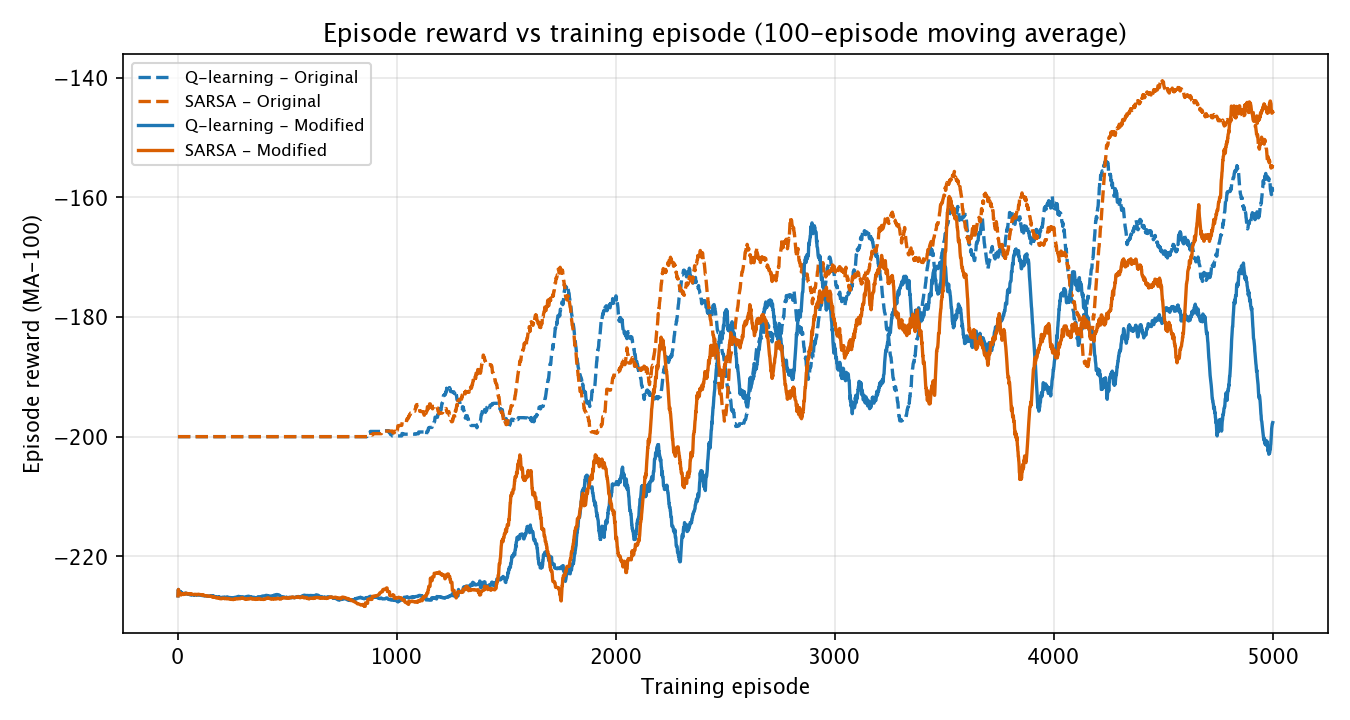

In [11]:
display(ShowImage(filename=os.path.join(OUT, "fig_reward.png")))

### Average max-Q on fixed validation states

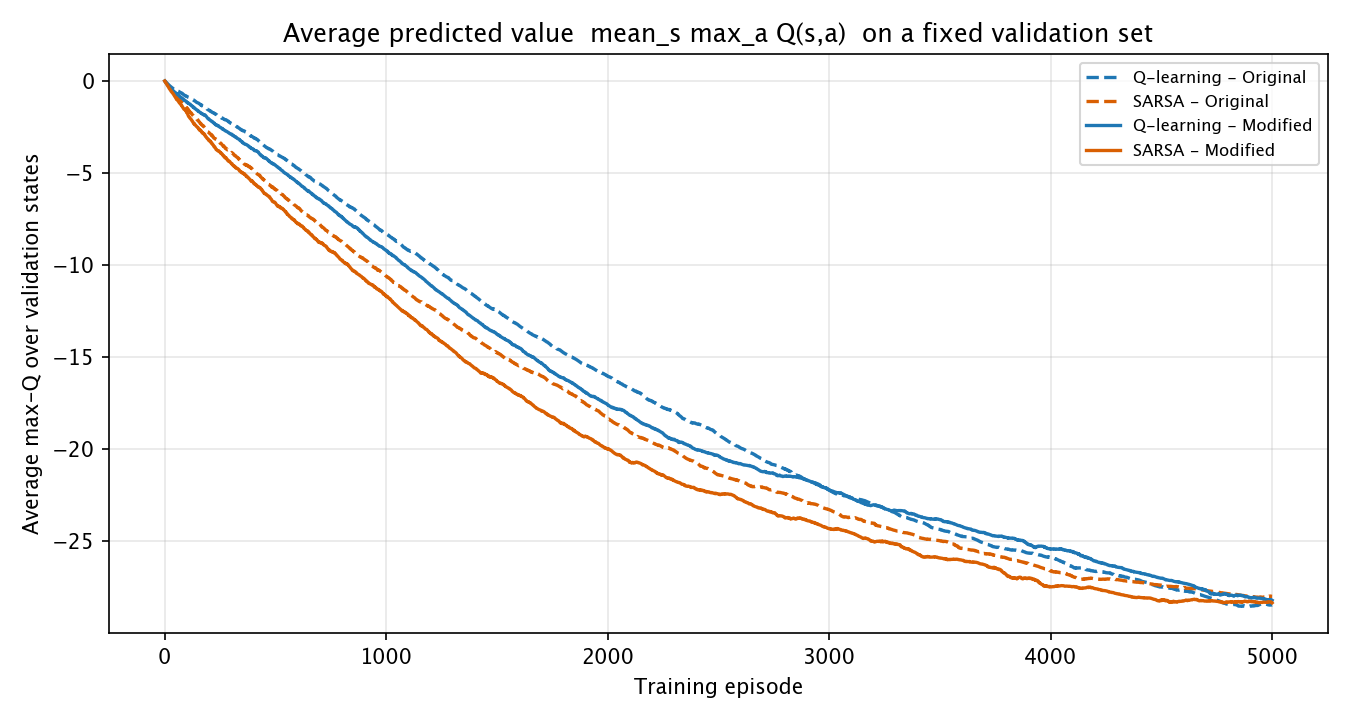

In [12]:
display(ShowImage(filename=os.path.join(OUT, "fig_value.png")))

### Success and gentle-arrival rate (MA-100)

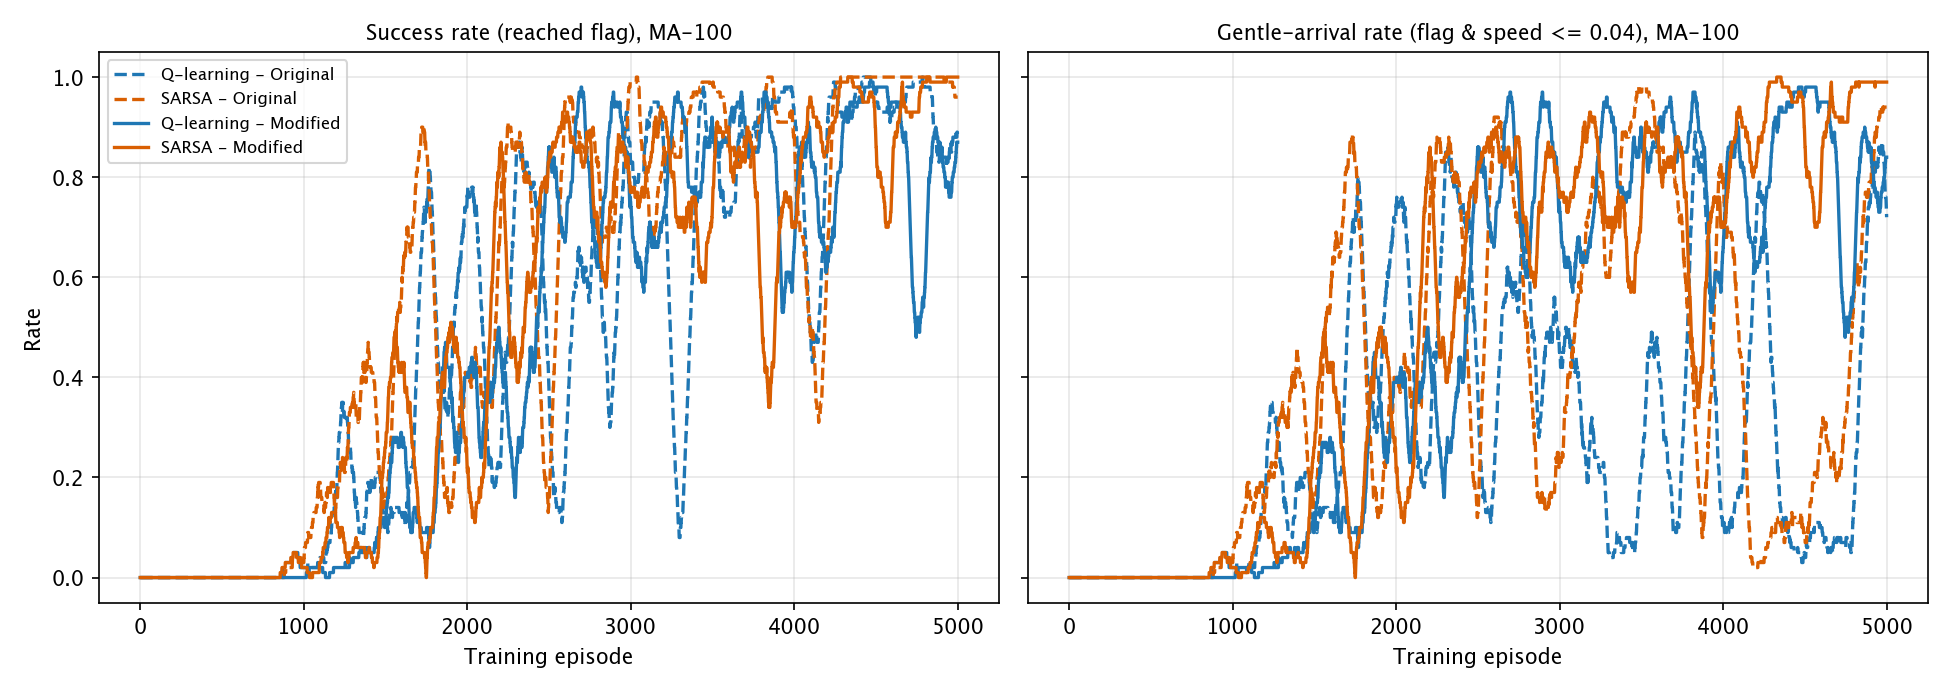

In [13]:
display(ShowImage(filename=os.path.join(OUT, "fig_success_gentle.png")))

### Push actions per episode (MA-100)

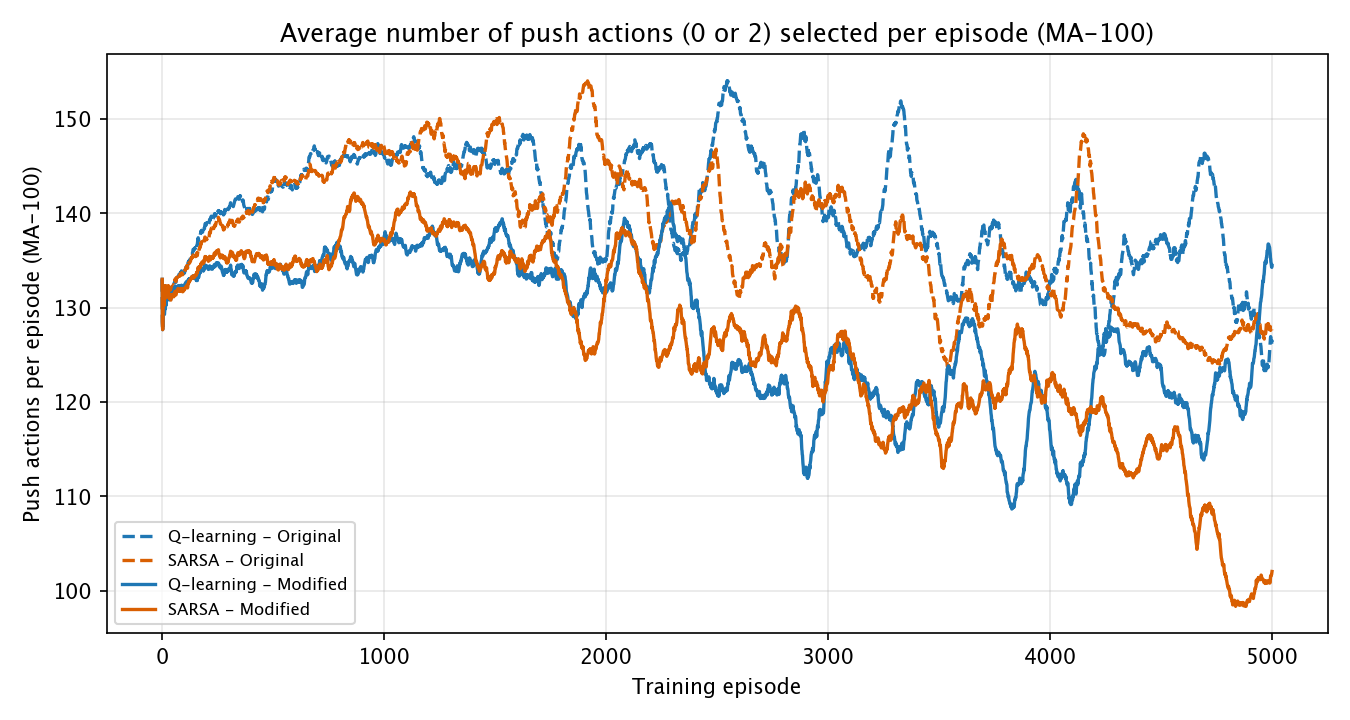

In [14]:
display(ShowImage(filename=os.path.join(OUT, "fig_pushes.png")))

### Greedy policy maps

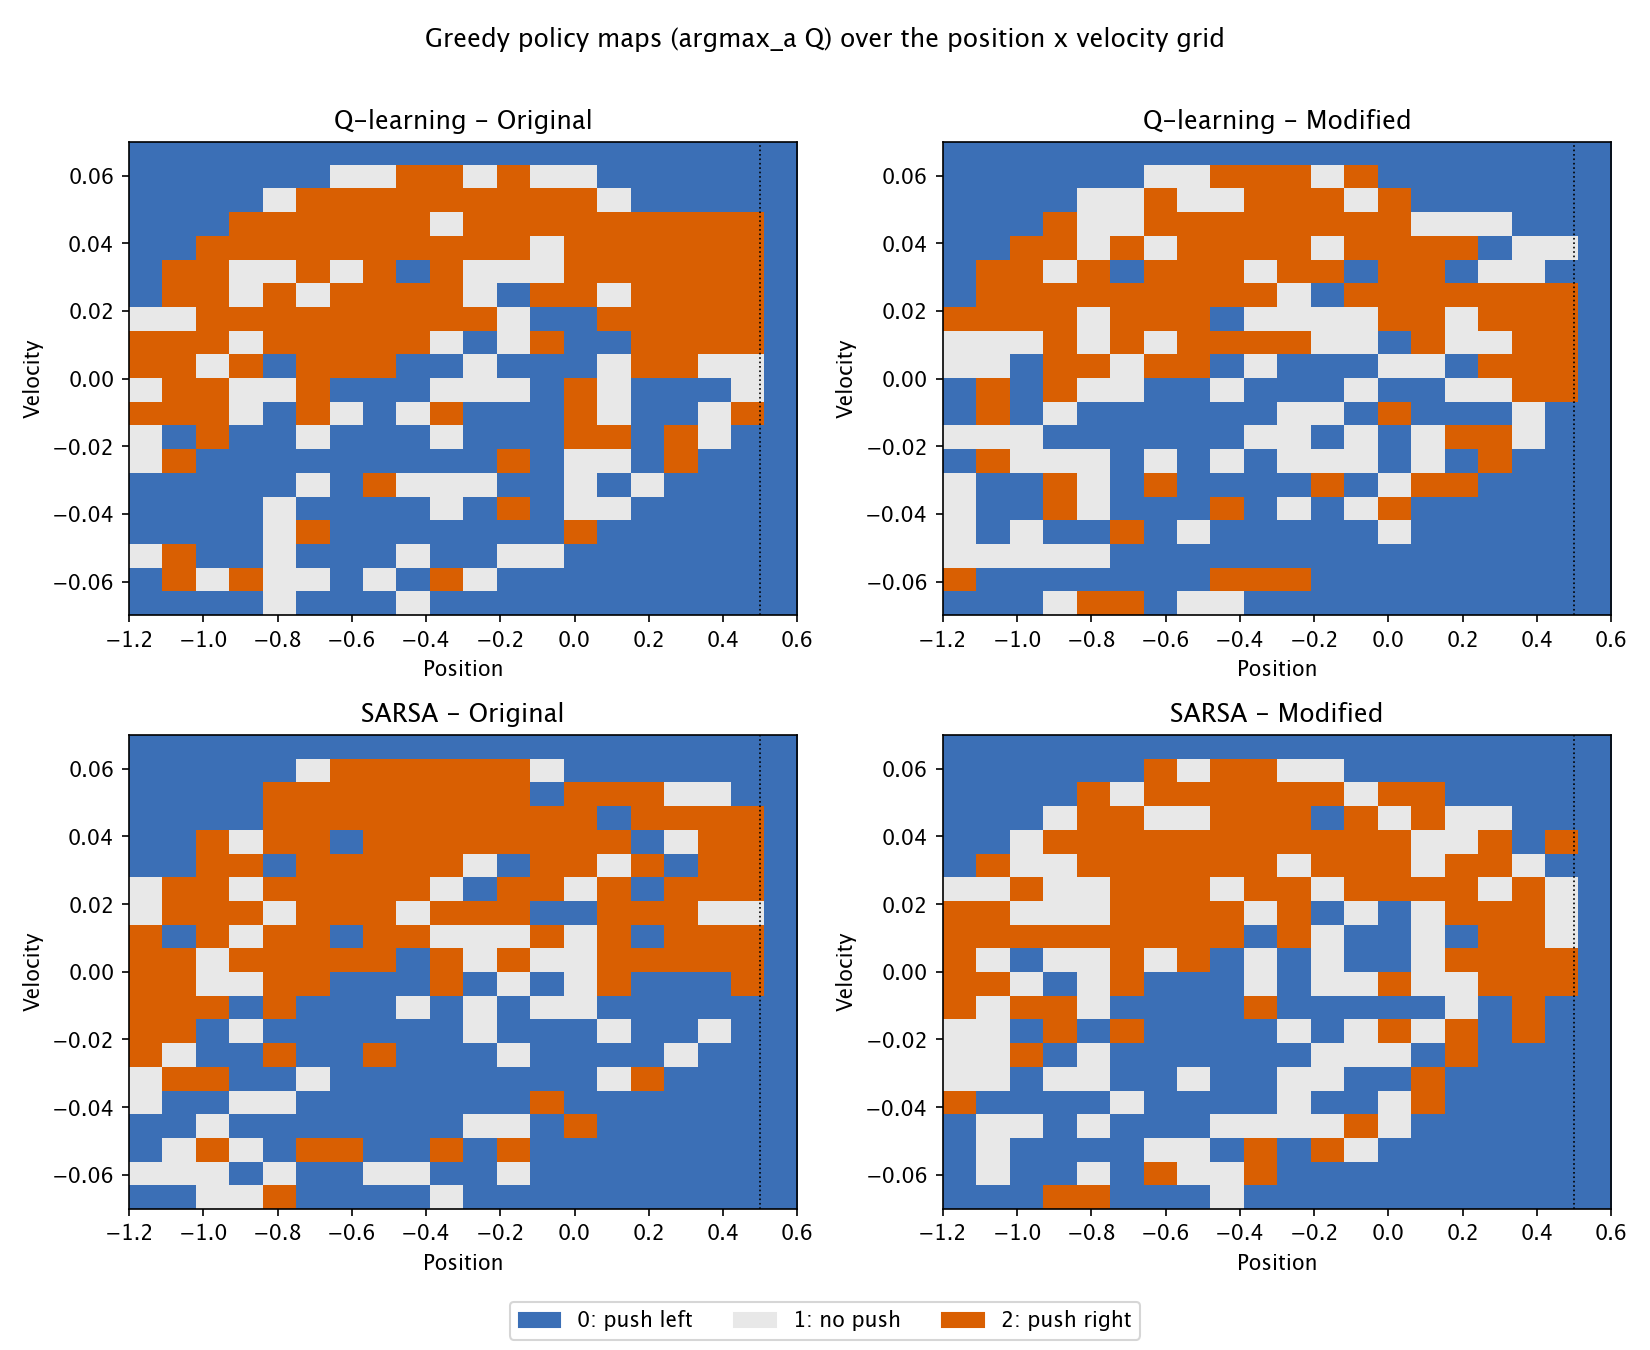

In [15]:
display(ShowImage(filename=os.path.join(OUT, "fig_policy_maps.png")))

## (d) Final greedy evaluation and summary tables

In [16]:
    P("\n######## PART (d): FINAL GREEDY EVALUATION (eps = 0, 100 test episodes, fixed seeds) ########")
    P(f"{'Agent':<26}{'Mean reward':>12}{'Success':>9}{'Gentle':>8}{'Mean len':>10}{'Arr. speed':>12}")
    for nm, (_, _, t) in res.items():
        P(f"{nm:<26}{t['mean_reward']:>12.2f}{t['success_rate']:>9.2f}{t['gentle_rate']:>8.2f}"
          f"{t['mean_length']:>10.1f}{t['mean_arrival_speed']:>12.4f}")

    P("\nTraining statistics over the LAST 500 training episodes (eps = 0.01):")
    P(f"{'Agent':<26}{'Reward':>9}{'Success':>9}{'Gentle':>8}{'Pushes/ep':>11}{'Length':>8}{'Avg max-Q':>11}")
    train_last = {}
    for nm, (_, log, _) in res.items():
        row = {k: last_mean(log, k) for k in ("reward", "success", "gentle", "pushes", "length")}
        row["val_value"] = float(log["val_value"][-1])
        train_last[nm] = row
        P(f"{nm:<26}{row['reward']:>9.1f}{row['success']:>9.3f}{row['gentle']:>8.3f}"
          f"{row['pushes']:>11.1f}{row['length']:>8.1f}{row['val_value']:>11.2f}")

    # value-estimate gap Q-learning minus SARSA (on the fixed validation states)
    P("\nValue-estimate gap  (Q-learning - SARSA) of avg max-Q on validation states:")
    gaps = {}
    for env_nm in ("Original", "Modified"):
        q = res[f"Q-learning - {env_nm}"][1]["val_value"]
        s = res[f"SARSA - {env_nm}"][1]["val_value"]
        gaps[env_nm] = dict(final=float(q[-1] - s[-1]), last500=float(np.mean(q[-500:] - s[-500:])),
                            mean_abs=float(np.mean(np.abs(q - s))),
                            q_final=float(q[-1]), s_final=float(s[-1]))
        P(f"  {env_nm:<9}: final gap = {gaps[env_nm]['final']:+.3f}   last-500 mean gap = "
          f"{gaps[env_nm]['last500']:+.3f}   mean |gap| over training = {gaps[env_nm]['mean_abs']:.3f}")

    # greedy policy agreement between algorithms (fraction of visited-or-not grid cells with same action)
    P("\nGreedy-policy agreement (fraction of grid cells with identical greedy action):")
    agree = {}
    for env_nm in ("Original", "Modified"):
        pa = greedy_policy_map(res[f"Q-learning - {env_nm}"][0])
        pb = greedy_policy_map(res[f"SARSA - {env_nm}"][0])
        agree[env_nm] = float(np.mean(pa == pb))
        P(f"  Q-learning vs SARSA, {env_nm}: {agree[env_nm]:.3f}")

    # push-action share on the policy map
    P("\nShare of grid cells whose greedy action is: left / none / right")
    share = {}
    for nm, (Q, _, _) in res.items():
        pol = greedy_policy_map(Q)
        share[nm] = [float(np.mean(pol == k)) for k in range(3)]
        P(f"  {nm:<24}: {share[nm][0]:.3f} / {share[nm][1]:.3f} / {share[nm][2]:.3f}")

    


######## PART (d): FINAL GREEDY EVALUATION (eps = 0, 100 test episodes, fixed seeds) ########
Agent                      Mean reward  Success  Gentle  Mean len  Arr. speed
Q-learning - Original          -164.57     0.87    0.12     164.6      0.0382
SARSA - Original               -176.79     0.56    0.56     176.8      0.0296
Q-learning - Modified          -185.81     0.71    0.71     174.6      0.0267
SARSA - Modified               -160.28     0.90    0.90     156.4      0.0202

Training statistics over the LAST 500 training episodes (eps = 0.01):
Agent                        Reward  Success  Gentle  Pushes/ep  Length  Avg max-Q
Q-learning - Original        -164.5    0.922   0.360      134.6   164.5     -28.47
SARSA - Original             -147.4    0.992   0.556      126.6   147.4     -28.02
Q-learning - Modified        -186.0    0.810   0.804      122.9   177.5     -28.23
SARSA - Modified             -156.9    0.942   0.936      104.9   154.6     -28.37

Value-estimate gap  (Q-learn

## Robustness over 5 seeds

In [17]:
    P("\n######## ROBUSTNESS: additional seeds (same hyper-parameters) ########")
    all_seeds = {CFG["seed"]: {nm: dict(test=t, train_last=train_last[nm]) for nm, (_, _, t) in res.items()}}
    gap_seeds = {CFG["seed"]: {e: gaps[e]["last500"] for e in gaps}}
    for sd in ROBUST_SEEDS:
        r = run_experiments(sd, val_states, disc)
        all_seeds[sd] = {nm: dict(test=t, train_last={k: last_mean(l, k) for k in ("reward", "success", "gentle", "pushes")})
                         for nm, (_, l, t) in r.items()}
        gap_seeds[sd] = {e: float(np.mean(r[f"Q-learning - {e}"][1]["val_value"][-500:]
                                           - r[f"SARSA - {e}"][1]["val_value"][-500:])) for e in ("Original", "Modified")}
    P("\nGreedy test metrics, mean +- std over %d seeds:" % len(all_seeds))
    cols = ("mean_reward", "success_rate", "gentle_rate", "mean_length", "mean_arrival_speed")
    P(f"{'Agent':<26}{'Mean reward':>16}{'Success':>13}{'Gentle':>13}{'Mean len':>15}{'Arr. speed':>16}{'Pushes/ep*':>16}")
    robust = {}
    for nm in res:
        arr = {k: np.array([all_seeds[s][nm]["test"][k] for s in all_seeds]) for k in cols}
        arr["train_pushes"] = np.array([all_seeds[s][nm]["train_last"]["pushes"] for s in all_seeds])
        robust[nm] = {k: (float(np.nanmean(v)), float(np.nanstd(v))) for k, v in arr.items()}
        P(f"{nm:<26}" + "".join(f"{robust[nm][k][0]:>{w1}.{d}f}+-{robust[nm][k][1]:<{w2}.{d}f}"
                                for k, w1, w2, d in (("mean_reward", 9, 6, 2), ("success_rate", 7, 5, 2),
                                                     ("gentle_rate", 7, 5, 2), ("mean_length", 9, 6, 1),
                                                     ("mean_arrival_speed", 9, 6, 4), ("train_pushes", 9, 6, 1))))
    P("(* Pushes/ep = selected push actions per episode, mean of the last 500 TRAINING episodes)")
    P("\nValue gap (Q-learning - SARSA), last-500-episode mean, per seed:")
    for e in ("Original", "Modified"):
        v = [gap_seeds[s][e] for s in gap_seeds]
        P(f"  {e:<9}: " + ", ".join(f"{x:+.2f}" for x in v) + f"   -> mean {np.mean(v):+.2f} +- {np.std(v):.2f}")
    gap_robust = {e: [float(np.mean([gap_seeds[s][e] for s in gap_seeds])),
                      float(np.std([gap_seeds[s][e] for s in gap_seeds]))] for e in ("Original", "Modified")}

    t_end = datetime.datetime.now()
    P(f"\nRun finished: {t_end.strftime('%Y-%m-%d %H:%M:%S')}  (elapsed {(t_end - t_start).total_seconds():.0f}s)")

    json.dump(dict(cfg=CFG, a=a_results,
                   test={nm: t for nm, (_, _, t) in res.items()}, train_last=train_last, gaps=gaps,
                   agree=agree, share=share, robust=robust, gap_robust=gap_robust,
                   n_robust_seeds=len(all_seeds), started=t_start.isoformat(), finished=t_end.isoformat()),
              open(os.path.join(OUT, "results.json"), "w"), indent=2)
    LOG.close()


######## ROBUSTNESS: additional seeds (same hyper-parameters) ########


  seed 1  Q-learning - Original    trained in  27.1s | test: mean_reward=-158.530, success_rate=0.990, gentle_rate=0.980, mean_length=158.530, mean_arrival_speed=0.025


  seed 1  SARSA - Original         trained in  25.2s | test: mean_reward=-145.720, success_rate=1.000, gentle_rate=1.000, mean_length=145.720, mean_arrival_speed=0.025


  seed 1  Q-learning - Modified    trained in  26.9s | test: mean_reward=-195.868, success_rate=0.920, gentle_rate=0.900, mean_length=185.820, mean_arrival_speed=0.027


  seed 1  SARSA - Modified         trained in  25.8s | test: mean_reward=-160.038, success_rate=0.970, gentle_rate=0.970, mean_length=157.940, mean_arrival_speed=0.023


  seed 2  Q-learning - Original    trained in  26.0s | test: mean_reward=-139.260, success_rate=1.000, gentle_rate=1.000, mean_length=139.260, mean_arrival_speed=0.030


... (7 outputs left out)

  seed 4  Q-learning - Original    trained in  26.5s | test: mean_reward=-171.330, success_rate=1.000, gentle_rate=1.000, mean_length=171.330, mean_arrival_speed=0.038


  seed 4  SARSA - Original         trained in  25.3s | test: mean_reward=-157.200, success_rate=1.000, gentle_rate=1.000, mean_length=157.200, mean_arrival_speed=0.040


  seed 4  Q-learning - Modified    trained in  26.9s | test: mean_reward=-132.988, success_rate=1.000, gentle_rate=1.000, mean_length=133.670, mean_arrival_speed=0.027


  seed 4  SARSA - Modified         trained in  26.0s | test: mean_reward=-154.758, success_rate=0.990, gentle_rate=0.980, mean_length=152.300, mean_arrival_speed=0.027

Greedy test metrics, mean +- std over 5 seeds:
Agent                          Mean reward      Success       Gentle       Mean len      Arr. speed      Pushes/ep*
Q-learning - Original       -159.46+-10.89    0.97+-0.05    0.82+-0.35     159.5+-10.9     0.0333+-0.0051    132.2+-1.5   
SARSA - Original            -156.73+-11.81    0.86+-0.18    0.85+-0.18     156.7+-11.8     0.0306+-0.0048    133.1+-5.1   
Q-learning - Modified       -175.44+-22.40    0.87+-0.12    0.87+-0.12     169.0+-18.3     0.0265+-0.0016    113.1+-5.8   
SARSA - Modified            -174.61+-21.11    0.82+-0.22    0.80+-0.24     167.3+-14.7     0.0234+-0.0026    115.6+-6.5   
(* Pushes/ep = selected push actions per episode, mean of the last 500 TRAINING episodes)

Value gap (Q-learning - SARSA), last-500-episode mean, per seed:
  Original : -0.36, 

## (e) Discussion
See the cell below (rendered from the same text as the PDF report).

**1. Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?**

Only weakly, and not conclusively. For the main seed the mean absolute gap between the two avg-max-Q curves over training grows from 1.38 (original) to 1.90 (modified), and the last-500-episode gap goes from -0.36 to +0.56. Over 5 seeds the last-500 gap is +0.49 +- 0.55 (original) versus +1.07 +- 1.06 (modified); it is larger in the modified environment for 4 of 5 seeds, but one seed (+3.16) drives most of the average and the intervals overlap, so we cannot claim a statistically reliable increase. This direction is plausible: with stochastic action execution the max operator in Q-learning's target picks the best of several noisy estimates, which inflates it relative to the on-policy expectation used by SARSA. However both value curves end at the same level (about -28) because exploration is small (eps = 0.01) at the end of training and the tables are not yet fully converged, which limits how far the two can differ. A cleaner test would use more seeds and longer training.

**2. Why is the modified environment non-Markovian with respect to the observation, and how does it affect credit assignment?**

The executed action depends on a_prev, which is part of the wrapper's internal state but not of the observation (position, velocity). The next-state distribution P(s' | s, a) therefore depends on the hidden variable: the same (s, a) gives a distribution that is 100% 'a' if a_prev = a, but 80% 'a' and 20% 'a_prev' otherwise. Because a_prev is a function of the agent's own recent history, the observation alone is not a sufficient statistic: the problem is a POMDP, and the tabular TD methods (which assume the Markov property) estimate values that average over the hidden a_prev under the visitation distribution of the current policy. Credit assignment suffers in three ways: (i) the reward and the next state are caused by a_exec, but the update credits the selected action a, so Q(s,a) is partly contaminated by the effect of a_prev; (ii) the energy penalty is charged to the selected action even when it was not executed, so a push that never happened is still punished (and a stuck push after selecting 1 is free); (iii) the +20 bonus arrives only at the last step but depends on the speed built up by the preceding sequence of executed actions, so the TD updates have to propagate it through noisier transitions, which slows and destabilises learning. The coarse discretization adds further aliasing (also present in the original environment). Empirically the modified-environment curves are noisier and the 5-seed test rewards worse (-175 vs -157 to -159 for the original environment, with larger spread).

**3. Do the energy penalty and the gentle-arrival bonus encourage fewer pushes or a slower, more controlled arrival?**

Both, with evidence for each. *Fewer pushes:* the push-count plot shows the modified agents' counts drifting down while the original agents' stay at 125-150; the 5-seed training means are 113-116 vs 132-133 pushes per episode (13-15% fewer), and the share of 'no push' cells in the policy maps rises from 18.2% / 15.5% to 22.5% / 23.0%. *Slower, more controlled arrival:* the greedy test arrival speed falls from 0.0333 / 0.0306 (Q-learning / SARSA, original) to 0.0265 / 0.0234 (modified) over 5 seeds, and the main-seed values from 0.038 / 0.030 to 0.027 / 0.020; the gentle-arrival rate is almost identical to the success rate in the modified environment (0.71 vs 0.71 and 0.90 vs 0.90 on the main-seed test set) but far below it for Q-learning in the original one (0.12 vs 0.87). The bonus (+20) dominates the incentive: the energy penalty (0.2) is small, so the agents still push in about two thirds of steps (82-86% in the original environment), and reducing pushes is a side effect rather than the main behaviour change.

**4. Which algorithm performs better under sticky actuators? Is this consistent with the on-policy / off-policy theory?**

For the main seed SARSA is clearly better in the modified environment (greedy test reward -160.3 vs -185.8, success 0.90 vs 0.71, mean length 156 vs 175). But this does **not** hold up across seeds: over 5 seeds the test reward is -174.6 +- 21.1 (SARSA) vs -175.4 +- 22.4 (Q-learning), and Q-learning has a slightly higher mean success rate (0.87 vs 0.82), all well inside the seed-to-seed spread (SARSA's modified-environment reward ranges from -209.6 to -154.8 across seeds). We therefore conclude that, in our setup, neither algorithm is reliably better; the main-seed gap is mostly seed variance. This is consistent with the theory: SARSA's advantage in classic examples such as Cliff Walking comes from its target including the exploratory behaviour of the policy it follows. The sticky actuator, however, is part of the environment dynamics, so *both* algorithms learn its effect from sampled transitions, and the on-policy/off-policy distinction only matters through the exploration rate, which is just 0.01 at the end of training. The only systematic differences we observed (SARSA arrives slightly more slowly, 0.0234 vs 0.0265, and with lower value estimates during training) are small relative to the noise.

**5. One limitation of the experimental setup and a possible improvement.**

**Limitation:** a single hidden-state-blind tabular setting with a 20 x 20 grid and 5 seeds. Hidden a_prev plus state aliasing make the learning curves very noisy (success rate oscillating between roughly 0.1 and 1.0 during training; seed-to-seed standard deviation of 11-22 in test reward), so differences of the size we are interested in between the algorithms cannot be resolved with the number of runs we made, and the value tables are still changing after 5,000 episodes. **Improvement:** run many more seeds (e.g. 30) and report confidence intervals / a paired test, train longer with a decaying learning rate, and use a better function approximator (e.g. tile coding) or eligibility traces (Q(lambda)/SARSA(lambda)), which propagate the sparse +20 bonus faster and are less sensitive to the aliasing introduced by the hidden a_prev. (Augmenting the state with the executed action would restore the Markov property, but it is excluded by the assignment because the executed action must stay hidden.)

## Virtual-lab screenshots
*(attach timestamped screenshots here)*